In [2]:
import pandas as pd

docs = pd.read_csv('../Dataset/CVF Conferences Dataset.csv')
data = docs[docs['CVF Conferences'] == 'CVPR 2015']

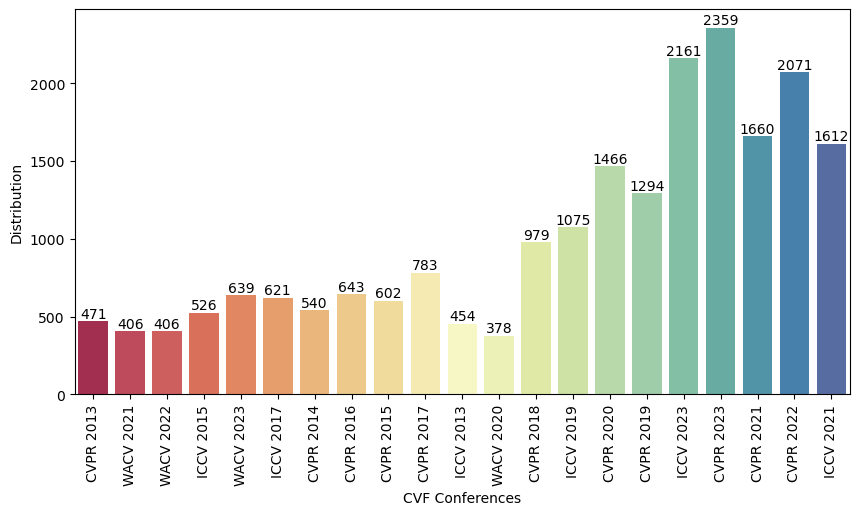

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
ax = sns.countplot(x=docs['CVF Conferences'], palette=sns.color_palette("Spectral", 21))
for container in ax.containers:
    ax.bar_label(container)
plt.xticks(rotation=90)
plt.ylabel('Distribution')
plt.xlabel('CVF Conferences')
plt.show()

In [ ]:
p

In [14]:
from bs4 import BeautifulSoup
import re

def preprocessing(text):
    new_text = re.sub(r'[\r\n\t]', '', text)
    return BeautifulSoup(new_text, "html.parser").get_text()

In [15]:
for col in data.columns:
    data[col] = data[col].astype(str).apply(preprocessing)

In [16]:
def cleanText(text):
    text = re.sub('https?:\/\/\S+', '', text) 
    text = re.sub('[^a-zA-Z]', ' ', str(text).lower().strip())
    text = re.sub('#','',text)
    text = re.sub('\d+', '', text)
    text = re.sub('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]+','', text) 
    text = re.sub('\n',' ',text)
    return text

data['Clean Abstract'] = data['Title'].apply(cleanText) 

In [17]:
from nltk import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

def removeStopwords(text):
    tokens = word_tokenize(text)
    lemmatizer = WordNetLemmatizer()
    clean_text = [lemmatizer.lemmatize(word) for word in tokens if word.lower() not in stopwords.words('english')]
    return ' '.join(clean_text)

data['Clean Abstract'] = data['Clean Abstract'].apply(removeStopwords)

In [18]:
def removeSuffix(text):
    text = re.sub(r'\b(\w+?)s\b', r'\1', text)
    return text
data['Clean Abstract'] = data['Clean Abstract'].apply(removeSuffix)
data

,CVF Conferences,Title,Abstract,Clean Abstract
32,CVPR 2015,Going Deeper With Convolutions,We propose a deep convolutional neural network...,going deeper convolution
34,CVPR 2015,Joint Action Recognition and Pose Estimation F...,Action recognition and pose estimation from vi...,joint action recognition pose estimation video
35,CVPR 2015,Fast Action Proposals for Human Action Detecti...,In this paper we target at generating generic ...,fast action proposal human action detection se...
36,CVPR 2015,Robust Reconstruction of Indoor Scenes,We present an approach to indoor scene reconst...,robust reconstruction indoor scene
820,CVPR 2015,On Pairwise Costs for Network Flow Multi-Objec...,Multi-object tracking has been recently approa...,pairwise cost network flow multi object tracking
...,...,...,...,...
1498,CVPR 2015,"What do 15,000 Object Categories Tell Us About...",This paper contributes to automatic classifica...,object category tell u classifying localizing ...
1499,CVPR 2015,Supervised Discrete Hashing,"Recently, learning based hashing techniques ha...",supervised discrete hashing
1500,CVPR 2015,Expanding Object Detector's Horizon: Increment...,Over the last several years it has been shown ...,expanding object detector horizon incremental ...
1501,CVPR 2015,Web Scale Photo Hash Clustering on A Single Ma...,This paper addresses the problem of clustering...,web scale photo hash clustering single machine


In [19]:
import cohere
from bertopic.backend import CohereBackend

client = cohere.Client("uK6NFd4g4w9zzQZYhtPEwKjymqeUxpDevAuylIjN")
embedding_model = CohereBackend(client)

# prompt = """
# I have topic that contains the following documents: [DOCUMENTS]
# The topic is described by the following keywords: [KEYWORDS].
# Based on the information above, can you give a short label of the topic?
# """

In [20]:
from transformers.pipelines import pipeline
from bertopic.representation import TextGeneration
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer

# generator = pipeline('text2text-generation', model='google/flan-t5-large')
# prompt = "Can you determine the subject or theme represented by these keywords: [KEYWORDS]?"
# representation = TextGeneration(generator, prompt)
# embedding_model = pipeline("feature-extraction", model="distilbert-base-cased")
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine')
hdbscan_model = HDBSCAN(min_cluster_size=15, metric='euclidean', cluster_selection_method='eom', prediction_data=True)
vectorizer_model = CountVectorizer(stop_words="english")
ctfidf_model = ClassTfidfTransformer()

In [21]:
from bertopic import BERTopic

topic_model = BERTopic(
    embedding_model=embedding_model,    # Step 1 - Extract embeddings
    umap_model=umap_model,              # Step 2 - Reduce dimensionality
    hdbscan_model=hdbscan_model,        # Step 3 - Cluster reduced embeddings
    vectorizer_model=vectorizer_model,  # Step 4 - Tokenize topics
    ctfidf_model=ctfidf_model,          # Step 5 - Extract topic words
    # representation_model={'Flan-T5': representation},
    verbose=True,
    calculate_probabilities=True,
    nr_topics=11
)

In [22]:
topics, probabilities = topic_model.fit_transform(data['Clean Abstract'])

2023-12-15 20:35:30,120 - BERTopic - Transformed documents to Embeddings
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
2023-12-15 20:35:35,007 - BERTopic - Reduced dimensionality
2023-12-15 20:35:35,032 - BERTopic - Clustered reduced embeddings
2023-12-15 20:35:35,053 - BERTopic - Reduced number of topics from 9 to 9


In [23]:
topic_model.generate_topic_labels()

['-1_image_shape_learning',
 '0_action_recognition_event',
 '1_face_unconstrained_facial',
 '2_saliency_detection_salient',
 '3_tracking_target_correlation',
 '4_estimation_image_camera',
 '5_object_segmentation_convolutional',
 '6_matching_graph_descriptor',
 '7_learning_image_visual']

In [24]:
topic_model.visualize_barchart(top_n_topics=10, n_words=10)

In [25]:
all_topics = topic_model.get_topic_info()
all_topics

,Topic,Count,Name,Representation,Representative_Docs
0,-1,131,-1_image_shape_learning_video,"[image, shape, learning, video, pose, model, p...",[combining local appearance holistic view dual...
1,0,35,0_action_recognition_event_video,"[action, recognition, event, video, human, hie...",[multi feature max margin hierarchical bayesia...
2,1,24,1_face_unconstrained_facial_recognition,"[face, unconstrained, facial, recognition, age...",[cros age face verification coordinating cros ...
3,2,18,2_saliency_detection_salient_visual,"[saliency, detection, salient, visual, deep, p...",[deep network saliency detection via local est...
4,3,24,3_tracking_target_correlation_tracker,"[tracking, target, correlation, tracker, multi...",[target identity aware network flow online mul...
5,4,134,4_estimation_image_camera_depth,"[estimation, image, camera, depth, reconstruct...",[accurate depth map estimation lenslet light f...
6,5,85,5_object_segmentation_convolutional_detection,"[object, segmentation, convolutional, detectio...",[object localization free weakly supervised le...
7,6,16,6_matching_graph_descriptor_region,"[matching, graph, descriptor, region, robust, ...",[matchnet unifying feature metric learning pat...
8,7,135,7_learning_image_visual_classification,"[learning, image, visual, classification, inst...",[deep multiple instance learning image classif...


In [26]:
# all_topics.to_csv('Flan-T5 Representation.csv', index=False)

In [27]:
from gensim import  corpora
from gensim.models.coherencemodel import CoherenceModel

def coherenceCalc(filtered_data, index):
    documents = pd.DataFrame({"Document": filtered_data['Clean Abstract'],
                            "ID": range(len(filtered_data['Clean Abstract'])),
                            "Topic": index})
    documents_per_topic = documents.groupby(['Topic'], as_index=False).agg({'Document': ' '.join})
    cleaned_docs = topic_model._preprocess_text(documents_per_topic.Document.values)

    vectorizer = topic_model.vectorizer_model
    analyzer = vectorizer.build_analyzer()

    words = vectorizer.get_feature_names_out()
    tokens = [analyzer(doc) for doc in cleaned_docs]
    dictionary = corpora.Dictionary(tokens)
    corpus = [dictionary.doc2bow(token) for token in tokens]

    topic_words = []
    for topic in range(len(set(topics))-topic_model._outliers):
        words = list(zip(*topic_model.get_topic(topic)))[0]
        words = [word for word in words if word in dictionary.token2id]
        topic_words.append(words)
    topic_words = [words for words in topic_words if len(words) > 0]

    coherence_model = CoherenceModel(topics=topic_words, 
                                    texts=tokens, 
                                    corpus=corpus,
                                    dictionary=dictionary, 
                                    coherence='c_v')
    coherence = coherence_model.get_coherence()
    return coherence

In [28]:
import numpy as np 

value = len(np.unique(topics))
length = list(range(value))
for start in length:
    index = [i for i, x in enumerate(topics) if x == start-1]
    filtered_data = data.iloc[index]
    coherence = coherenceCalc(filtered_data, index)
    print('Keywords:' + str(all_topics['Representation'][start]) + '| Coherence:' + str(coherence))
    

Keywords:['image', 'shape', 'learning', 'video', 'pose', 'model', 'person', 'based', 'deep', 'using']| Coherence:0.4503543275841515
Keywords:['action', 'recognition', 'event', 'video', 'human', 'hierarchical', 'detection', 'deep', 'activity', 'book']| Coherence:0.3450534153294318
Keywords:['face', 'unconstrained', 'facial', 'recognition', 'age', 'alignment', 'cascade', 'using', 'verification', 'landmark']| Coherence:0.33145891919133835
Keywords:['saliency', 'detection', 'salient', 'visual', 'deep', 'prediction', 'context', 'assisted', 'attentionally', 'automaton']| Coherence:0.3100694672975961
Keywords:['tracking', 'target', 'correlation', 'tracker', 'multi', 'detection', 'adaptive', 'foreground', 'reliable', 'object']| Coherence:0.3906630236206557
Keywords:['estimation', 'image', 'camera', 'depth', 'reconstruction', 'stereo', 'single', 'resolution', 'based', 'motion']| Coherence:0.44528695660436707
Keywords:['object', 'segmentation', 'convolutional', 'detection', 'network', 'semantic'